# VisA PCB의 정상·불량 판정 | EfficientNet-B0
PCB1~PCB4로 학습한 모델의 결과를 **원본 이미지 단위**로 확인한다. 정상은 0, 불량은 1이다. 한 원본에서 자른 모든 타일 중 가장 높은 불량 확률을 그 원본의 점수로 쓴다.

`deeppcb` 폴더에서 `python -m src3.07_train_visa`를 실행해 결과를 저장한 후 이 노트북을 위에서부터 읽는다. 아래 셀은 `src3/artifacts_visa`의 저장 결과를 사용한다.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image as InlineImage, display
from PIL import Image

# 기본 0.5 판정은 "default", 검증에서 선택한 판정은 "operating"
DETAIL_MODE = "operating"
if DETAIL_MODE not in {"default", "operating"}:
    raise ValueError('DETAIL_MODE는 "default" 또는 "operating"이어야 합니다.')

def find_src3():
    for base in (Path.cwd(), *Path.cwd().parents):
        for suffix in ("", "src3", "deeppcb/src3", "DeepPCB/deeppcb/src3",
                       "data_example/DeepPCB/deeppcb/src3"):
            folder = base / suffix
            if (folder / "07_train_visa.py").is_file():
                return folder
    raise FileNotFoundError("프로젝트 또는 src3 폴더에서 노트북을 열어 주세요.")

root = find_src3() / "artifacts_visa"
prepared = root / "prepared"
run = root / "runs" / "VisA"
if not (run / "test/evaluation.json").is_file():
    raise FileNotFoundError(f"시험 결과가 없습니다. 07_train_visa.py 실행 후 확인하세요. {run}")

def read_json(path):
    return json.loads(path.read_text(encoding="utf-8-sig"))

cfg = read_json(run / "config.json")
info = read_json(run / "run.json")
decision = read_json(run / "threshold.json")
test = pd.read_csv(run / "test/metrics.csv")
predictions = pd.read_csv(run / "test/predictions.csv")
if set(predictions["source"]) != {"VisA"} or predictions["image_id"].duplicated().any():
    raise ValueError("시험 예측의 출처 또는 원본 ID 중복을 확인하세요.")

## 데이터 분할과 타일
PCB 종류와 정상·불량 라벨별로 원본을 먼저 분할한다. 아래 표에서 원본 수와 타일 수를 구분해 볼 수 있다. 불량 영역의 일부만 걸쳐 학습 대상에서 제외한 타일도 원본 판정 시에는 사용한다.

,split,originals,original_normal,original_defect,all_tiles,tile_normal,tile_defect,tile_excluded
0,train,3091,2811,280,18546,17616,828,102
1,validation,663,603,60,3978,3772,179,27
2,test,662,602,60,3972,3768,178,26


label             정상 원본  불량 원본
board split                   
pcb1  test          150     15
      train         703     70
      validation    151     15
pcb2  test          150     15
      train         701     70
      validation    150     15
pcb3  test          151     15
      train         704     70
      validation    151     15
pcb4  test          151     15
      train         703     70
      validation    151     15

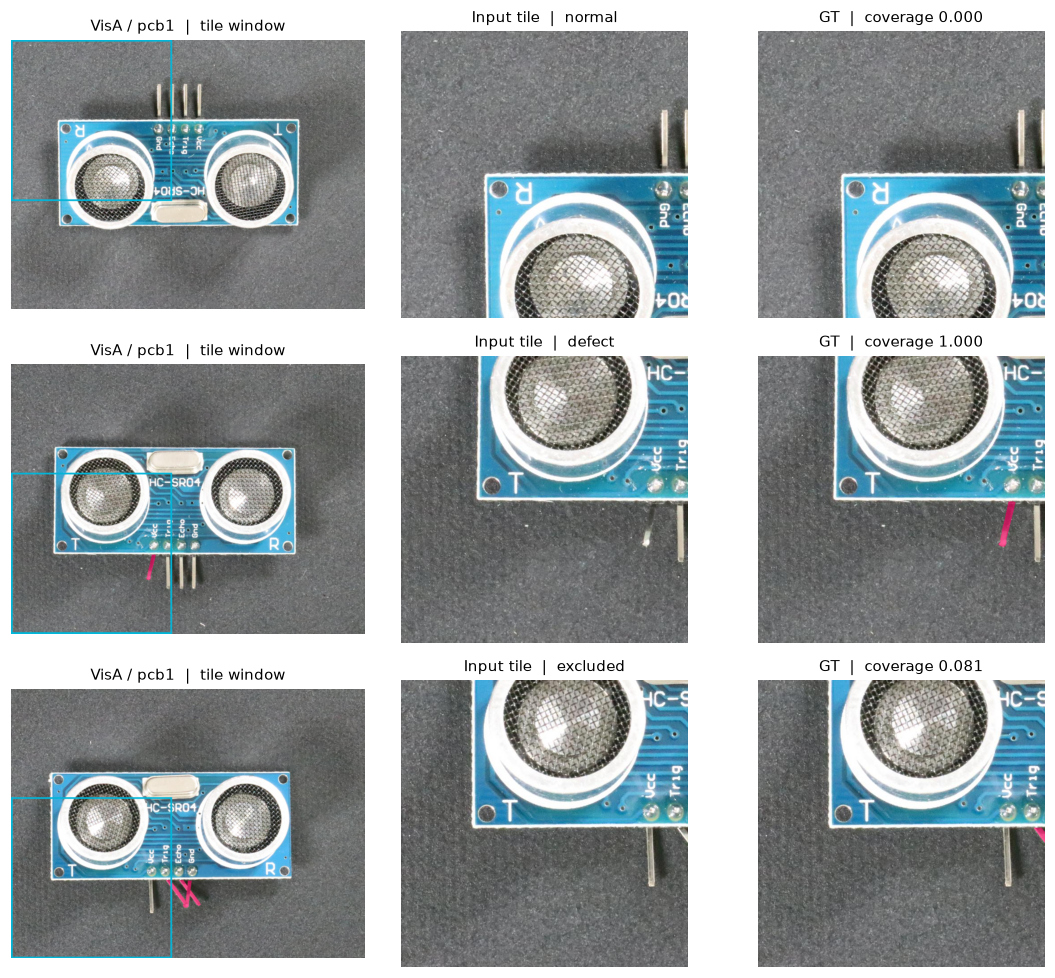

In [2]:
counts = pd.read_csv(prepared / "counts.csv")
display(counts[["split", "originals", "original_normal", "original_defect",
                "all_tiles", "tile_normal", "tile_defect", "tile_excluded"]])
splits = pd.read_csv(run / "splits.csv")
by_board = pd.crosstab([splits["board"], splits["split"]], splits["label"])
display(by_board.rename(columns={0: "정상 원본", 1: "불량 원본"}))
display(InlineImage(filename=str(prepared / "previews/VisA.png")))

## 학습 곡선과 체크포인트
왼쪽은 에폭별 학습·검증 손실이고 오른쪽은 임계값 0.5에서의 검증 지표다. 검증 원본의 로그 손실이 가장 낮은 에폭을 선택한다.

최적 에폭 2 / 검증 원본 로그 손실 0.2269


,model,pretrained,epochs,batch_size,optimizer,learning_rate,imbalance
0,efficientnet_b0,True,3,48,adamw,0.0002,class_weight


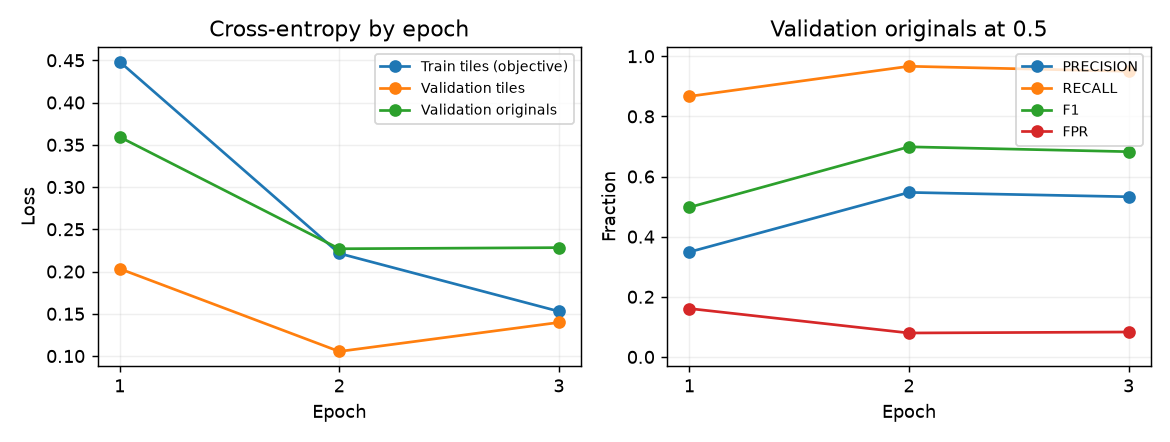

,epoch,train_loss,val_tile_loss,val_image_loss,val_recall,val_f1
0,1,0.448290,0.203290,0.359258,0.866667,0.497608
1,2,0.221414,0.105403,0.226932,0.966667,0.698795
2,3,0.152873,0.139735,0.228271,0.950000,0.682635


In [3]:
print(f"최적 에폭 {info['best_epoch']} / 검증 원본 로그 손실 {info['best_validation_image_log_loss']:.4f}")
display(pd.DataFrame([cfg["training"]])[["model", "pretrained", "epochs", "batch_size",
                                         "optimizer", "learning_rate", "imbalance"]])
display(InlineImage(filename=str(run / "learning_curves.png")))
history = pd.read_csv(run / "history.csv")
display(history[["epoch", "train_loss", "val_tile_loss", "val_image_loss", "val_recall", "val_f1"]])

## 검증에서 결정한 운영 임계값
검증 원본에서 정상 오탐률(FPR) 상한과 불량 재현율(recall) 목표를 적용한다. 아래에서 실제 선택값, 목표 충족 여부, 기본 임계값과의 차이를 확인한다.

In [4]:
print(f"목표 recall ≥ {decision['policy']['min_recall']:.1%}, FPR ≤ {decision['policy']['max_fpr']:.1%}")
print(f"운영 임계값 {decision['threshold']:.6f} / 목표 충족 {decision['targets_met']}")
print(decision["reason"])
columns = ["mode", "threshold", "n_normal", "n_defect", "fp", "fn", "accuracy",
           "precision", "recall", "f1", "fpr", "fnr", "roc_auc", "pr_auc"]
validation = pd.read_csv(run / "validation/metrics.csv")
display(validation.loc[validation["scope"] == "all", columns].round(4))

목표 recall ≥ 90.0%, FPR ≤ 5.0%
운영 임계값 0.737457 / 목표 충족 True
Both targets met. Maximize recall, then minimize FPR, then choose closest to 0.5.


,mode,threshold,n_normal,n_defect,fp,fn,accuracy,precision,recall,f1,fpr,fnr,roc_auc,pr_auc
0,default,0.5000,603,60,48,2,0.9246,0.5472,0.9667,0.6988,0.0796,0.0333,0.9876,0.9081
8,operating,0.7375,603,60,19,6,0.9623,0.7397,0.9000,0.8120,0.0315,0.1000,0.9876,0.9081


## 시험 원본 성능과 보드별 결과
정상 이미지가 불량으로 판정되면 오탐(FP), 불량 이미지가 정상으로 판정되면 미검출(FN)이다. 전체 표는 두 임계값을 모두 표시한다. 아래 혼동행렬과 보드별 표에는 설정 셀의 `DETAIL_MODE`를 적용한다.

,mode,threshold,n_normal,n_defect,fp,fn,accuracy,precision,recall,f1,fpr,fnr,roc_auc,pr_auc
0,default,0.5000,602,60,33,4,0.9441,0.6292,0.9333,0.7517,0.0548,0.0667,0.9868,0.9188
8,operating,0.7375,602,60,14,10,0.9637,0.7812,0.8333,0.8065,0.0233,0.1667,0.9868,0.9188


,n_normal,n_defect,tn,fp,fn,tp,recall,fpr,f1
scope,,,,,,,,,
VisA/pcb1,150,15,150,0,7,8,0.5333,0.0000,0.6957
VisA/pcb2,150,15,145,5,0,15,1.0000,0.0333,0.8571
VisA/pcb3,151,15,149,2,3,12,0.8000,0.0132,0.8276
VisA/pcb4,151,15,144,7,0,15,1.0000,0.0464,0.8108


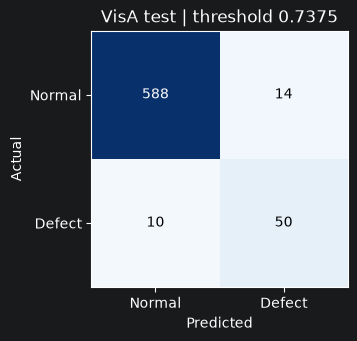

In [5]:
display(test.loc[test["scope"] == "all", columns].round(4))
view = test.loc[test["mode"] == DETAIL_MODE].set_index("scope")
display(view.loc[view.index.str.startswith("VisA/"), [
    "n_normal", "n_defect", "tn", "fp", "fn", "tp", "recall", "fpr", "f1"
]].round(4))

row = view.loc["all"]
matrix = [[int(row.tn), int(row.fp)], [int(row.fn), int(row.tp)]]
fig, ax = plt.subplots(figsize=(4, 3.3), layout="constrained")
ax.imshow(matrix, cmap="Blues", vmin=0)
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(matrix[i][j]), ha="center", va="center",
                color="white" if matrix[i][j] > max(map(max, matrix)) / 2 else "black")
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Normal", "Defect"],
       yticklabels=["Normal", "Defect"], xlabel="Predicted", ylabel="Actual",
       title=f"VisA test | threshold {row.threshold:.4f}")
plt.show()

## 오탐·미검출 원본
표에는 선택한 임계값에서 틀린 원본의 경로와 불량 점수를 표시한다. 그림은 오탐 중 점수가 가장 높은 원본과 미검출 중 점수가 가장 낮은 원본을 한 장씩 보여준다.

In [6]:
pred_col = f"pred_{DETAIL_MODE}"
errors = predictions.loc[predictions["label"] != predictions[pred_col]].copy()
errors["구분"] = errors["label"].map({0: "오탐", 1: "미검출"})
fp = errors.loc[errors["label"] == 0].sort_values("prob_defect", ascending=False)
fn = errors.loc[errors["label"] == 1].sort_values("prob_defect")
assert (len(fp), len(fn)) == (row.fp, row.fn), "원본별 판정과 지표가 일치하지 않습니다."
print(f"시험 원본 {len(predictions):,}장 중 오분류 {len(errors)}장 (오탐 {len(fp)}, 미검출 {len(fn)})")
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(pd.concat([fp, fn])[["구분", "board", "path", "label", pred_col, "prob_defect"]])

시험 원본 662장 중 오분류 24장 (오탐 14, 미검출 10)


,구분,board,path,label,pred_operating,prob_defect
659,오탐,pcb4,pcb4/Data/Images/Normal/0990.JPG,0,1,0.939330
513,오탐,pcb4,pcb4/Data/Images/Normal/0020.JPG,0,1,0.915298
231,오탐,pcb2,pcb2/Data/Images/Normal/0297.JPG,0,1,0.858946
646,오탐,pcb4,pcb4/Data/Images/Normal/0894.JPG,0,1,0.848078
661,오탐,pcb4,pcb4/Data/Images/Normal/0995.JPG,0,1,0.837366
643,오탐,pcb4,pcb4/Data/Images/Normal/0866.JPG,0,1,0.836309
297,오탐,pcb2,pcb2/Data/Images/Normal/0797.JPG,0,1,0.835489
306,오탐,pcb2,pcb2/Data/Images/Normal/0868.JPG,0,1,0.775266
655,오탐,pcb4,pcb4/Data/Images/Normal/0952.JPG,0,1,0.774384
650,오탐,pcb4,pcb4/Data/Images/Normal/0907.JPG,0,1,0.768890


오탐 · pcb4/Data/Images/Normal/0990.JPG · 불량 점수 0.9393


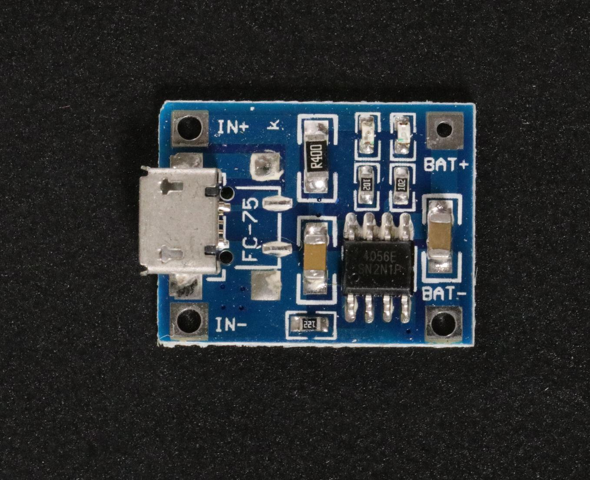

미검출 · pcb3/Data/Images/Anomaly/072.JPG · 불량 점수 0.2854


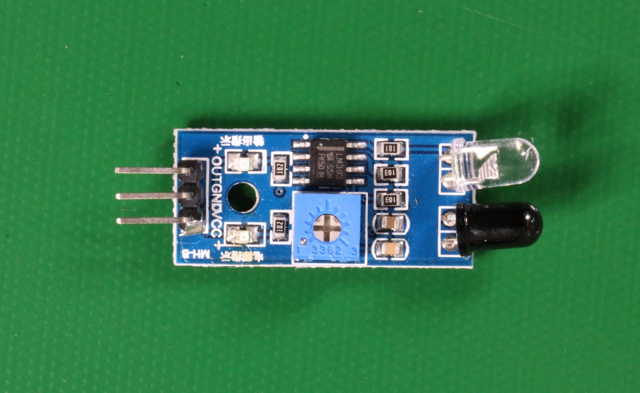

In [7]:
image_root = Path(cfg["paths"]["VisA"])
for example in pd.concat([fp.head(1), fn.head(1)]).to_dict("records"):
    path = image_root / example["path"]
    print(f"{example['구분']} · {example['path']} · 불량 점수 {example['prob_defect']:.4f}")
    if path.is_file():
        with Image.open(path) as img:
            thumb = img.convert("RGB")
            thumb.thumbnail((640, 480))
            display(thumb)
    else:
        print(f"원본 경로를 확인하세요. {path}")